# **데이터셋**

url: https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/penguins.csv


| 컬럼명 | 설명 |
|---|---|
| culmen_length_mm | 새의 부리 위쪽 능선(culmen, 쿨멘)의 길이(mm) |
| culmen_depth_mm | 부리의 세로 높이(두께)(mm) |
| flipper_length_mm | 펭귄의 팔(지느러미 형태의 날개) 길이(mm) |
| body_mass_g | 펭귄의 무게 (g) |
| sex | **[target]** 성별(남/녀) |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/penguins.csv")
pd.DataFrame(df.columns, columns=["column"])

,column
0,culmen_length_mm
1,culmen_depth_mm
2,flipper_length_mm
3,body_mass_g
4,sex


## **중복행 제거**

In [2]:
df.duplicated().sum()

np.int64(1)

In [3]:
df = df.drop_duplicates()

In [4]:
df = df.drop("sex", axis = 1)

## **결측치**

In [5]:
df.isnull().sum()

culmen_length_mm     1
culmen_depth_mm      1
flipper_length_mm    1
body_mass_g          1
dtype: int64

In [6]:
df = df.dropna()

In [7]:
df.isnull().sum()

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
dtype: int64

## **이상치 탐지**

In [8]:
def find_whisker(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    iqr = Q3 - Q1
    lower = Q1 - 1.5 * iqr
    upper = Q3 + 1.5 * iqr
    return (lower, upper)

In [9]:
d = {}
for c in df.columns:
    lower, upper = find_whisker(df, c)
    d[c] = (lower, upper)
    outliers = ((df[c] < lower) | (df[c] > upper)).sum()
    print(f"{c}: {outliers}")
    

culmen_length_mm: 0
culmen_depth_mm: 0
flipper_length_mm: 2
body_mass_g: 0


In [10]:
df[(df["flipper_length_mm"] >= 5000)  | (df["flipper_length_mm"] <= 0)].index

df = df.drop(df[(df["flipper_length_mm"] >= 5000)  | (df["flipper_length_mm"] <= 0)].index)

In [11]:
d = {}
for c in df.columns:
    lower, upper = find_whisker(df, c)
    d[c] = (lower, upper)
    outliers = ((df[c] < lower) | (df[c] > upper)).sum()
    print(f"{c}: {outliers}")

culmen_length_mm: 0
culmen_depth_mm: 0
flipper_length_mm: 0
body_mass_g: 0


## **인코딩**

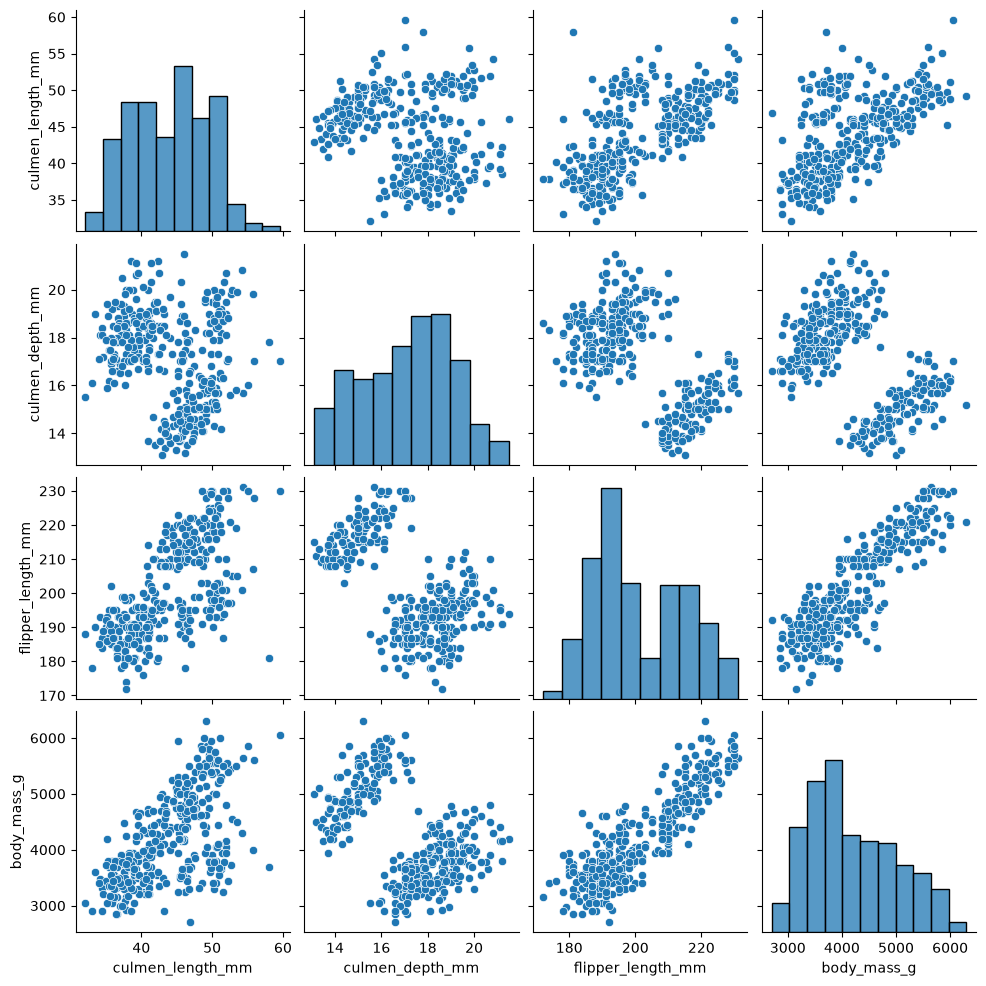

In [ ]:
sns.pairplot(df)
plt.show()

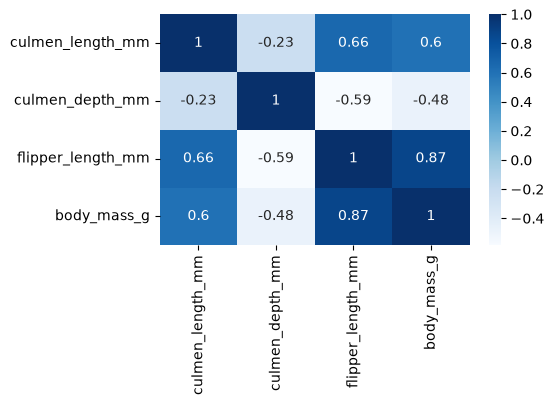

In [13]:
plt.figure(figsize=(5,3))
sns.heatmap(df.corr(), annot=True, cmap="Blues")
plt.show()

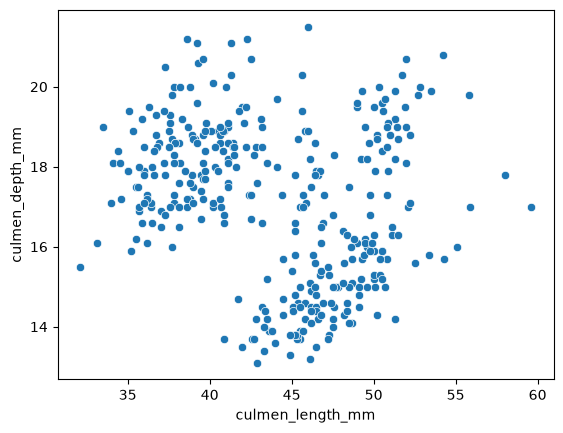

In [14]:
sns.scatterplot(df, x = "culmen_length_mm", y = "culmen_depth_mm")
plt.show()

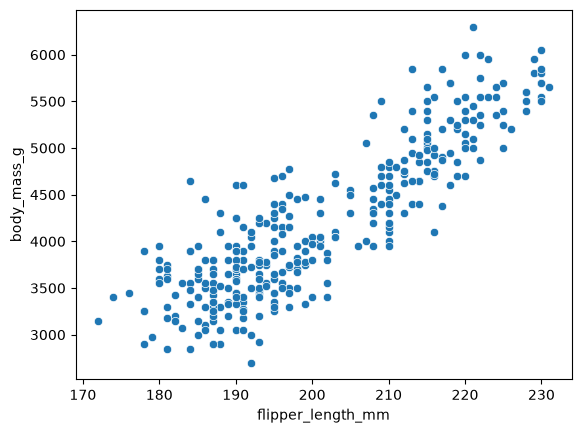

In [15]:
sns.scatterplot(df, x ="flipper_length_mm", y = "body_mass_g")
plt.show()

## **다중공선성 확인하기**

In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant # 한 열에 다 1점부터 시작

# 데이터에 기준점을 하나 추가 -> 학습할 때 추가되면 안됨.
X_vif =add_constant(df) # X_train이라는 dataframe에 constant라는 1로만 구성되어 있는 열을 하나 추가
X_vif.head()

,const,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,1.0,39.1,18.7,181.0,3750.0
1,1.0,39.5,17.4,186.0,3800.0
2,1.0,40.3,18.0,195.0,3250.0
4,1.0,36.7,19.3,193.0,3450.0
5,1.0,39.3,20.6,190.0,3650.0


In [17]:
# 각각의 열이 빠졌을 때 얼마만큼 결과에 영향을 미치는가
vif = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
# 깔끔한 시각화를 위함
vif_df = pd.DataFrame()
vif_df["feature"] = X_vif.columns
vif_df["VIF"] = vif

vif_df

# VIF 값을 해석하는 방법
# 1: 다중공선성 절대 없다.
# 5 이하인 값들 : 상관관계는 있으나, 다중공선성 자체는 없다고 봐도 무방
# 5 ~ 10 : 다중공선성이 있다
# 10 이상 : 아주 심각한 다중공선성이 존재 ->  이 정보는 반드시 feauture engineering이 필요

,feature,VIF
0,const,1.000000
1,culmen_length_mm,1.894985
2,culmen_depth_mm,1.637684
3,flipper_length_mm,5.959948
4,body_mass_g,4.223858


In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_scaled = scaler.fit_transform(df)

In [21]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier

## **모델 평가**

In [20]:
# from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
# def evaluate_model(y_true, y_pred):
#     print(f"accuray: {accuracy_score(y_test, y_pred)}")
#     print(classification_report(y_true, y_pred))
#     plt.figure(figsize=(5,3))
#     sns.heatmap(confusion_matrix(y_test, y_pred), cmap = "Blues", annot = True)
#     plt.show()